# Minimal example with MODFLOW simulation

THis notebook provided a minimal exapnel of how to use the `vorflow` to generate a mesh and the use it in a `MODFLOW` simulation.

In [189]:
from shapely.geometry import LineString, Point, box
from vorflow import ConceptualMesh, MeshGenerator, VoronoiTessellator
import flopy
import os
import matplotlib.pyplot as plt
import geopandas as gpd
import shutil

## Definition of the conceptual model

In [190]:

domain = box(0, 0, 200, 200)
well_point = Point(25, 25)
fault_line = LineString([(100, 0), (100, 150)])

cm = ConceptualMesh(crs="EPSG:3857")
cm.add_polygon(domain, zone_id=1)
cm.add_point(
    well_point,
    point_id="Well-A",
    resolution=2,
    growth_factor=1.2,
)
cm.add_line(
    fault_line,
    line_id="Fault-1",
    resolution=1,
    is_barrier=True,
)

clean_polys, clean_lines, clean_pts = cm.generate()


Applying optional geometry simplification...
Resolving polygon overlaps...
Enforcing strict topology...
Snapping 1 lines to polygon boundaries (tol=0.001)...
Snapping 1 points to geometry (tol=0.001)...
Clipping features to domain...
Densifying geometry...


## Create the `MeshCenerator` object

In [191]:

mg = MeshGenerator(background_lc=100)
mg.generate(clean_polys, clean_lines, clean_pts)



Transferring Geometry to Gmsh...
Constructed Barrier Zone from 1 protected features.
Adding 1 polygons to Gmsh...
Fragmenting 304 objects...
Reconstructing Map (Input Tags: 304, Out Map Len: 304)...
Explicitly embedding features into domain surfaces...
Setting up Resolution Fields...
Generating Triangular Mesh...
Running 2 Optimization Cycles (Relocate2D & Laplace2D)...


True

## Create the voronoi mesh

In [192]:

vt = VoronoiTessellator(mg, cm, clip_to_boundary=True)
gdf = vt.generate()

Extracting 2372 Nodes from Gmsh...
Computing Mathematical Voronoi...
  -> Raw Polygons: 2372
  -> After Ghost Filter: 2372
Clipping to Domain Boundary...
  -> After Domain Clip: 2372
Enforcing Hydrogeological Zones (Optimization: Point Sampling)...
  -> Zones Assigned: 2372
Enforcing Barrier Cuts on 1 lines...
  -> After Barrier Cuts: 2372
Final Voronoi Grid Generated: 2372 cells.


The voronoi mesh looks like this

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

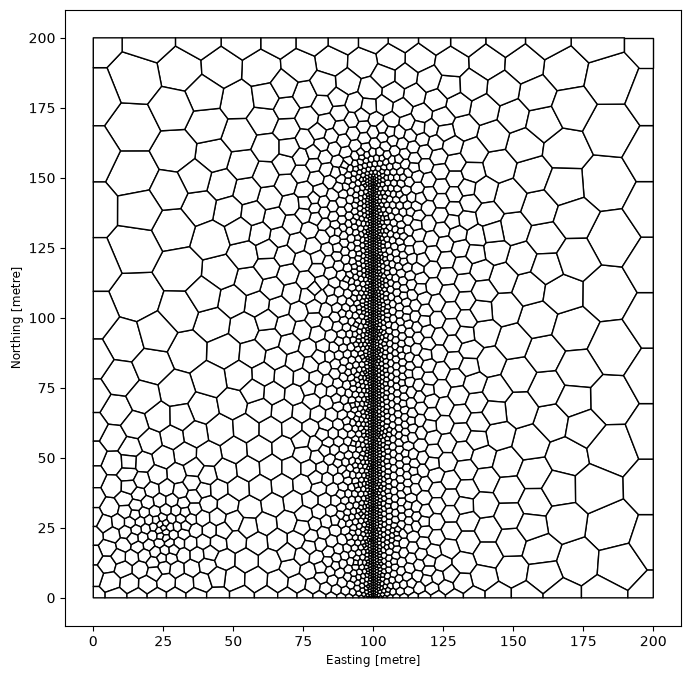

In [193]:

fig, ax = plt.subplots(figsize=(8,8))
gdf.plot(ax=ax, color='w', edgecolor='k')


## Create the `MODFLOW` model using `flopy`

In [194]:
# 1. Assuming 'gdf' is your GeoDataFrame containing the Voronoi polygons
# Let's ensure all geometries are clean Polygons
gdf = gdf[gdf.geometry.type == 'Polygon'].copy()

# 2. Extract all unique vertices from the Voronoi geometries
all_coords = []
for poly in gdf.geometry:
    # poly.exterior.coords contains the boundary points
    all_coords.extend(list(poly.exterior.coords)[:-1]) # drop the duplicated closing point

# Get unique coordinates while preserving a unique index ID for each
unique_coords, indices = np.unique(all_coords, axis=0, return_index=False), None 
# A cleaner way to index unique vertices using a dictionary:
vertex_map = {}
vertices_list = []
v_idx = 0

for poly in gdf.geometry:
    for x, y in poly.exterior.coords[:-1]:
        pt = (round(x, 4), round(y, 4)) # round slightly to avoid float precision mismatch
        if pt not in vertex_map:
            vertex_map[pt] = v_idx
            vertices_list.append([v_idx, x, y])
            v_idx += 1

nvert = len(vertices_list)

# 3. Build the cell2d array
cell2d_list = []
for i, poly in enumerate(gdf.geometry):
    centroid = poly.centroid
    xc, yc = centroid.x, centroid.y
    
    # Extract vertices and find their global ID mapping
    # Note: Shapely exterior coordinates are counter-clockwise by default.
    # MODFLOW 6 prefers clockwise ordering. We can reverse them if needed.
    poly_coords = list(poly.exterior.coords)[:-1]
        
    iv_list = [vertex_map[(round(x, 4), round(y, 4))] for x, y in poly_coords]
    ncvert = len(iv_list)
    
    # Format: [icell2d, xc, yc, ncvert, *vertices]
    cell_entry = [i, xc, yc, ncvert] + iv_list
    cell2d_list.append(cell_entry)

ncpl = len(gdf)

# 4. Initialize FloPy MODFLOW 6 Simulation
tmp_folder = "./_temp"
name = "voronoi_sim"
sim = flopy.mf6.MFSimulation(sim_name=name, exe_name="mf6", sim_ws=tmp_folder)
tdis = flopy.mf6.ModflowTdis(sim, nper=1, perioddata=[(1.0, 1, 1.0)])
ims = flopy.mf6.ModflowIms(sim, complexity="MODERATE")

# 5. Create Groundwater Flow (GWF) Model adn Initial Conditions (IC)
gwf = flopy.mf6.ModflowGwf(sim, modelname=name)
ic = flopy.mf6.ModflowGwfic(gwf, strt=20.0) # Initial head of 20 m for all cells

# 6. Define the DISV Package using your GeoPandas arrays
nlay = 1  # Number of vertical layers
top = 100.0
botm = [0.0]  # Bottom elevation for layer 1

disv = flopy.mf6.ModflowGwfdisv(
    gwf,
    nlay=nlay,
    ncpl=ncpl,
    nvert=nvert,
    top=top,
    botm=botm,
    vertices=vertices_list,
    cell2d=cell2d_list
)

# Set up basic Node Property Flow (required for flow calculations and HFB)
npf = flopy.mf6.ModflowGwfnpf(
    gwf, 
    icelltype=1, 
    k=10.0,      # Default hydraulic conductivity 
    save_flows=True
)

print(f"Successfully created DISV grid with {ncpl} cells and {nvert} vertices!")


Successfully created DISV grid with 2372 cells and 4596 vertices!


In [195]:
# Create boundary lines
left_line = LineString([(0, 0), (0, 200)])
right_line = LineString([(200, 0), (200, 200)])

# --- Spatial Queries ---
# 1. Left Boundary Cells (20 m head)
left_cells = gdf[gdf.intersects(left_line)].index.tolist()

# 2. Right Boundary Cells (10 m head)
right_cells = gdf[gdf.intersects(right_line)].index.tolist()

# 3. Well Cell (5 m head)
# Find the single cell containing the well point
well_cell = gdf[gdf.contains(well_point)].index[0]

In [196]:
# Find all cells touching the fault
fault_cells = gdf[gdf.intersects(fault_line)].index.tolist()

hfb_data = []
# Loop through candidate cells to find adjacent pairs along the fault
for i in range(len(fault_cells)):
    for j in range(i + 1, len(fault_cells)):
        c1 = fault_cells[i]
        c2 = fault_cells[j]
        
        # Get the shared boundary line between the two cells
        shared_edge = gdf.geometry.iloc[c1].intersection(gdf.geometry.iloc[c2])
        
        # If they share an edge, check if that edge lies on the fault line
        if not shared_edge.is_empty and shared_edge.geom_type in ['LineString', 'MultiLineString']:
            # Use a small buffer to account for minor floating point differences
            if shared_edge.within(fault_line.buffer(1e-3)):
                # Format: ((layer, cellid1), (layer, cellid2), hydraulic_factor)
                # Hydraulic factor = K / thickness. Set to 0.0 for completely impermeable.
                hfb_data.append(((0, c1), (0, c2), 0.0))


In [197]:

# 1. Consolidate ALL boundary data into a single list
chd_period_data = []

# Add left boundary cells (20 m)
for cid in left_cells:
    chd_period_data.append(((0, cid), 20.0))

# Add right boundary cells (10 m)
for cid in right_cells:
    chd_period_data.append(((0, cid), 10.0))

# Add well cell (5 m)
# Ensure well_cell is an integer, or handle it if it's a list/Index
if hasattr(well_cell, '__iter__'):
    for w_cid in well_cell:
        chd_period_data.append(((0, w_cid), 5.0))
else:
    chd_period_data.append(((0, well_cell), 5.0))

# 2. Initialize exactly ONE CHD Package for the model
chd = flopy.mf6.ModflowGwfchd(
    gwf, 
    stress_period_data={0: chd_period_data},
    pname="chd_main" # Explicit name prevents random index suffixes
)

print(f"Single consolidated CHD package initialized with {len(chd_period_data)} bounds.")



# --- 2. Horizontal Flow Barrier (HFB) ---
if hfb_data:
    maxhfb = len(hfb_data)
    
    hfb = flopy.mf6.ModflowGwfhfb(
        gwf,
        print_input=True,
        maxhfb=maxhfb,
        stress_period_data=hfb_data  # Changed to stress_period_data
    )
    print(f"Impermeable fault applied across {len(hfb_data)} cell faces.")

# --- Initial Conditions (IC) Package ---
# MODFLOW 6 requires a starting point to begin its mathematical iterations
init_head = 20.0  


print("Initial Conditions package added successfully.")

# --- Output Control (OC) Package ---
# You must explicitly tell MODFLOW 6 to save the heads to a file
head_filename = f"{gwf.name}.hds"
budget_filename = f"{gwf.name}.cbc"

oc = flopy.mf6.ModflowGwfoc(
    gwf,
    head_filerecord=[head_filename],
    budget_filerecord=[budget_filename],
    saverecord=[("HEAD", "ALL"), ("BUDGET", "ALL")],
    printrecord=[("HEAD", "ALL"), ("BUDGET", "ALL")]
)
print("Output Control package configured to save heads.")




Single consolidated CHD package initialized with 29 bounds.
Impermeable fault applied across 150 cell faces.
Initial Conditions package added successfully.
Output Control package configured to save heads.


writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model voronoi_sim...
    writing model name file...
    writing package ic...
    writing package disv...
    writing package npf...
    writing package chd_main...
INFORMATION: maxbound in ('', 'chd', 'dimensions') changed to 29 based on size of stress_period_data
    writing package hfb...
    writing package oc...
FloPy is using the following executable to run the model: ../../../../../.local/bin/mf6
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                            VERSION 6.7.0 02/05/2026

   MODFLOW 6 compiled Feb 05 2026 22:38:38 with Intel(R) Fortran Intel(R) 64
   Compiler Classic for applications running on Intel(R) 64, Version 2021.6.0
                             Build 20220226_000000

This software has been approved for release by the U.S. Geological 
Survey (USGS). 

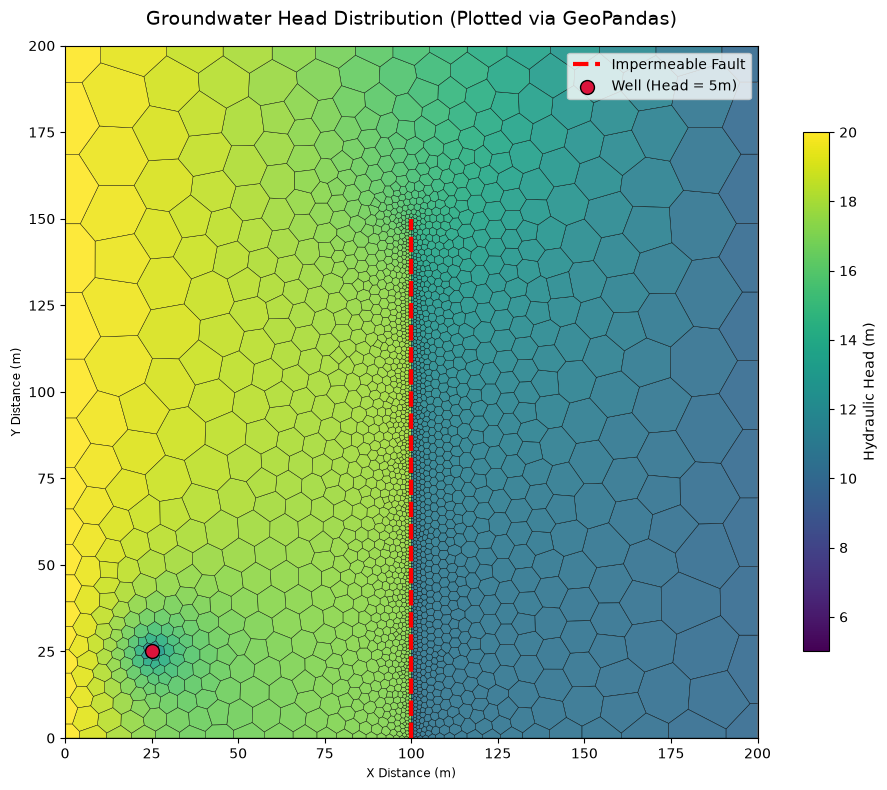

In [198]:
# 1. Run the simulation and extract the heads
sim.write_simulation()
success, buff = sim.run_simulation()

if success:
    model_name = gwf.name 
    head_file = os.path.join(".", f"{tmp_folder}/{model_name}.hds")
    hds_obj = flopy.utils.binaryfile.HeadFile(head_file)
    heads = hds_obj.get_data(kstpkper=(0, 0)) # Shape is typically (nlay, ncpl)
    
    # 2. Extract the head array for the top layer (Layer 0)
    # heads[0] will be a 1D array of length 'ncpl' matching the number of cells
    layer_0_heads = heads[0]
    
    # 3. Save the head results directly into your GeoDataFrame
    # Assumes your cells in 'gdf' are in the exact same index order as cell2d_list
    gdf['hydraulic_head'] = layer_0_heads[0]
    print("Successfully attached hydraulic head data to GeoDataFrame!")

    # 4. Generate the plot using GeoPandas
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot the Voronoi polygons colored by their hydraulic head values
    gdf.plot(
        column='hydraulic_head',
        cmap='viridis',
        edgecolor='black',
        linewidth=0.3,
        alpha=0.9,
        legend=True,
        legend_kwds={'label': "Hydraulic Head (m)", 'shrink': 0.75},
        ax=ax
    )
    
    # 5. Overlay original geometric features
    # Plot the Fault line (Impermeable Barrier)
    fx, fy = fault_line.xy
    ax.plot(fx, fy, color="red", linestyle="--", linewidth=3, label="Impermeable Fault")
    
    # Plot the Well location
    ax.scatter(well_point.x, well_point.y, color="crimson", marker="o", s=100, 
               edgecolors="black", zorder=5, label="Well (Head = 5m)")

    # 6. Formatting
    ax.set_title("Groundwater Head Distribution (Plotted via GeoPandas)", fontsize=14, pad=15)
    ax.set_xlabel("X Distance (m)")
    ax.set_ylabel("Y Distance (m)")
    ax.set_xlim(0, 200)
    ax.set_ylim(0, 200)
    ax.set_aspect('equal')
    ax.legend(loc="upper right")
    
    plt.tight_layout()
    plt.show()

else:
    print("Simulation failed. Cannot extract heads.")

# Delete the temporary files
shutil.rmtree(tmp_folder, ignore_errors=True)
